# Test GOTM Operators

In this notebook, we demonstrate how to use the PyTorch operators provided by the _tridiag_ package that simulate vertical (one-dimensional) advection and diffusion of tracers in a fluid.

We will first use the advection and diffusion operators for performing a single time step while demonstrating different numerical settings.

Then, we will use the full transport operator to perform a longer rollout of the operators. Doing so, we will demonstrate the use of a simple tracer model, the _PassiveModel_, that features a constant sinking velocity for tracers suspended in water.

In [ ]:
import matplotlib.pyplot as plt
import torch

from marinade.gotm.diffusion import DiffusionOperator
from marinade.gotm.advection import AdvectionOperator

from marinade.gotm.gotm import TracerSimulationOperator
from marinade.fabm.passive_model import PassiveModel

## Vertical advection

First, let's try the advection step. Advection uses an explicit scheme, so no tridiagonal matrix solving is required. However, there are a number of schemes for the computation of fluxes.

The advection operator can be used in one of two modes: conservative or non-conservative. In the case of conservative advection, the integrated tracer concentration is conserved and we solve the equation:

$\frac{\partial Y}{\partial t} = -\frac{\partial F}{\partial z}$,

where $Y$ is the Eulerian tracer concentration field, $t$ is time, $z$ is the vertical coordinate, $w$ is the vertical velocity component and $F=w\,Y$ is the flux of the tracer. As the outflux of one cell is always the influx of another cell (except for the boundary fluxes which are usually zero), this equation conserves the total tracer mass.

However, often, vertical advection is considered as part of a higher-dimensional scenario, e.g. 3d. In such a case, there might be a horizontal velocity divergence which requires a vertical divergence as well, following the continuity equation
$\frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} + \frac{\partial w}{\partial z} = 0$. In such a case, the total tracer mass of one water column is, in fact, not conserved, but changes due to the horizontal advection. When modelling such a scenario in a 1d simulation, we thus use the non-conservative advection equation:

$\frac{\partial Y}{\partial t} = -(\frac{\partial F}{\partial z} - Y \frac{\partial w}{\partial z}) = -w \frac{\partial Y}{\partial z}$

Here, the intuition is that a vertical velocity divergence does not change the tracer concentration because the vertical in-/outflux corresponds to a horizontal out-/influx.

We now define a conservative advection operator for a simulation with 110 vertical levels:

In [ ]:
adv_op = AdvectionOperator(bc_up_type="flux", bc_down_type="flux", bc_up_value=0., bc_down_value=0., scheme="p2_pdm", conserve=True)

This is a good choice for modelling e.g. sinking of a passive tracer that sinks when suspended in water.

There are multiple limiter schemes available. There are relevant for the numerical computation of the fluxes. They are computed in an upstream-biased way:

$F_i^n = \frac{1}{\Delta t}\int_{z_i^{\text{Face}}-w\Delta t}^{z_i^{\text{Face}}} Y(z') \mathrm{dz'}$

For a third-order polynomial approximation of these fluxes, we use the Lax-Wendroff form:

$F_i = \begin{cases}
    w_i \left(Y_{i\phantom{+1}} + \frac{1}{2}\Phi_i^+(1-|c_i|)(Y_{i+1}-Y_i)\right) & \text{for\quad} w_i>0, \\
    w_i \left(Y_{i+1} + \frac{1}{2}\Phi_i^-(1-|c_i|)(Y_i-Y_{i+1})\right) & \text{for\quad} w_i<0
\end{cases}$

$c_i=2w_i\Delta t/(h_i+h_{i+1})$ is called the Courant number, and $\Phi_i^\pm$ are parameters depending on the concentration gradient. For numerical reasons, these are usually limited by flux limiter schemes in order to ensure numerical stability.

In this implementation, several slope limiter schemes are available. Which one should be used depends on the application. For now, we use the third-order scheme (TVD) with ULTIMATE QUICKEST limiter (P2_PDM).

Now, we want to apply the operator and define a set of initial and forcing conditions. Note that we already defined no-flux boundary conditions in the definition of our operator.

In [ ]:
init_state = (8.15 + torch.exp(-(torch.arange(0, 110)-50)**2/5)).unsqueeze(0).unsqueeze(0)  # shape [batch, tracer, z]
h = torch.ones((1, 1, 110), dtype=torch.float64)  # layer heights, shape [batch, tracer, z]
dt = 60.0  # numerical time step [s]
w = torch.full((1, 1, 111), -86.4/(60**2*24))  # velocity, shape [batch, tracer, z+1]: defined at cell faces, not centers
w[:, :, [0, -1]] = 0  # no flux at the boundaries, thus no velocity

Note that the velocity is defined at the cell faces and therefore is one larger in the vertical dimension. However, our operators can also handle velocities defined at the cell centers. They then do a linear interpolation at the faces using the spatial information (the _h_ heights).

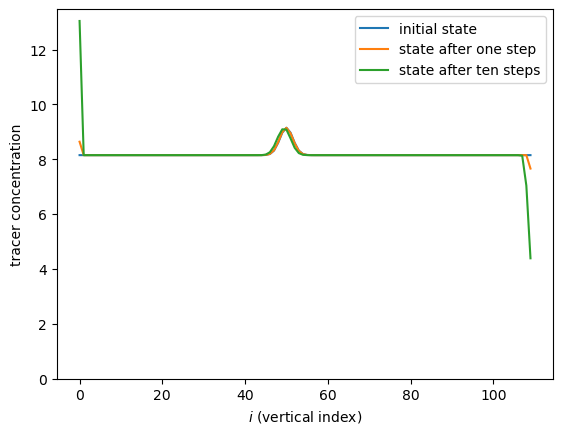

In [ ]:
state1 = adv_op(init_state, dt, h, w)
state2 = state1
for i in range(9):
    state2 = adv_op(state2, dt, h, w)
plt.plot(init_state.squeeze(), label='initial state')
plt.plot(state1.squeeze(), label='state after one step')
plt.plot(state2.squeeze(), label='state after ten steps')
plt.xlabel("$i$ (vertical index)")
plt.ylabel("tracer concentration")
plt.ylim(bottom=0)
plt.legend()
plt.show()

As we see, the fluid concentration decreases at the top and increases at the bottom, as we would expect due to the negative sinking velocity. Note that negative velocities indicate sinking while positive velocities indicate rising – the positive direction is defined upwards. Also note that the indexing of the vertical dimension starts at zero at the bottom and increases upwards, following the upwards-positive convention.

## Vertical diffusion

Now, we consider the diffusion of tracers in a fluid. In particular, note that our diffusion operator is meant to be used for turbulent diffusion. This means that the diffusivity is not a result of Brownian motion, but emerges due to turbulent mixing of a fluid. This effect is usually much stronger in the scenarios we care about, which would be mainly rivers and oceans. The General Ocean Turbulence Model (GOTM) which served as the basis for our framework is, indeed, a model for turbulent mixing. However, in the following, we will refer to our diffusivities simply as diffusivities without mentioning the physical background of the diffusion. Indeed, our operators work independently of the source of the diffusivities.

First, let us note the diffusion equation:

$\frac{\partial c}{\partial t} = \frac{\partial}{\partial z}\left(\nu_c\frac{\partial c}{\partial z}\right)
     + c L + Q$

Again, $c$ is the tracer concentration field, $t$ is time and $z$ is the vertical coordinate. Now, $\nu_c$ is the diffusivity field of tracer $c$. Note, however, that the turbulent diffusivity does not depend on the kind of the tracer, but only on the turbulent motion of the water. Thus, the distinction by the tracer is not necessary in our case and we can simply write $\nu$. However, our framework is able to use distinct diffusivities per tracer. Finally, we have a linear and a constant source/sink term, $L$ and $Q$. Those might be zero in some applications, but can also be used for external in- and outfluxes.

We define our diffusion operator and our diffusivity field:

In [ ]:
dif_op = DiffusionOperator(bc_up_type="neumann", bc_down_type="neumann", bc_up_value=0., bc_down_value=0., implicitness=1., allow_negative=False, method="paracr")

nu = torch.full((1, 1, 111), 0.1)  # shape [batch, z+1]: defined at cell faces, not centers

Again, we define no-flux von Neumann boundary conditions at the top and bottom boundaries. As the tracer concentrations are always positive, we set _allow_negative_ to False.

Now, note that the operator has a parameter for the implicitness. Typically, the diffusion equation is solved using an implicit scheme, in contrast to the explicit advection algorithm we previously introduced. Also, a semi-implicit scheme may be employed by choosing an implicitness in [0, 1], e.g. 0.5 (Crank-Nicolson).

Now, we want to demonstrate the use of the operator:

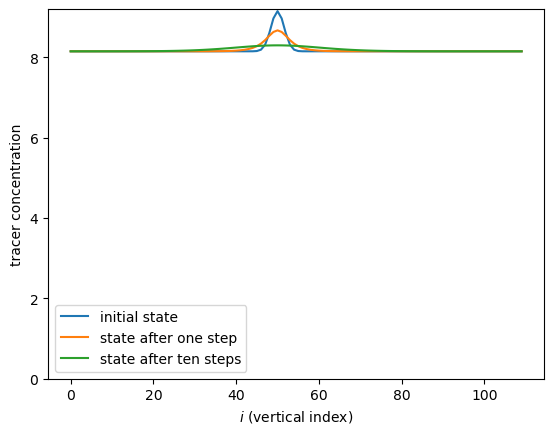

In [ ]:
state1 = dif_op(init_state, dt, h, nu)
state2 = state1
for i in range(9):
    state2 = dif_op(state2, dt, h, nu)
plt.plot(init_state.squeeze(), label='initial state')
plt.plot(state1.squeeze(), label='state after one step')
plt.plot(state2.squeeze(), label='state after ten steps')
plt.xlabel("$i$ (vertical index)")
plt.ylabel("tracer concentration")
plt.ylim(bottom=0)
plt.legend()
plt.show()

Indeed, we see that the initial concentration peak decreases over time while the concentration in the surrounding region increases.

## Run full simulation

Now, we will compute a longer rollout of our operators in a realistic scenario. For that, we use a custom diffusivity profile that changes over time due to an onset of turbulence.

In a full simulation setup, the advection and diffusion operators are typically coupled to a biogeochemical (BGC) model that computes local source and sink terms. For demonstration purposes, however, we use a passive model with a constant sinking velocity and no further BGC exchanges. However, it does inherit from our BaseModel class and thus can be used for demonstrating our unified BGC model API.

First, we set up a simple model with a constant sinking velocity:

In [ ]:
model = PassiveModel(torch.tensor(-86.4/(60**2*24), dtype=torch.float64))

This model has multiple functions. First of all, it computes the sinking velocity of our tracer:

In [ ]:
print("sinking velocity:", model.get_vertical_movement(init_state, h, test_argument="this argument is not implemented"))

sinking velocity: tensor([[[-0.0010]]])


This outputs the sinking velocity specified in the creation of the object. However, more advanced models might compute the sinking velocity as a function of the current state, and they might also provide different sinking velocities depending on the kind of tracer. Note that our API might be extended to additional input arguments for this function in the case that more complex models need them. The function is defined such that it accepts additional input arguments in order to ensure future compatibility.

As an instance of a BaseModel, the PassiveModel can also compute a forward step of the supposed biological processes. However, as those are not implemented, it simply returns the input state:

In [ ]:
print("total difference of initial and final state of biological processes:", torch.sum(torch.abs(init_state - model(init_state, dt=dt, h=h, dynamic_inputs=None))).item())

total difference of initial and final state of biological processes: 0.0


We now define a turbulent diffusivity field with a small initial diffusivity that increases after 20 hours, first on the bottom layers:

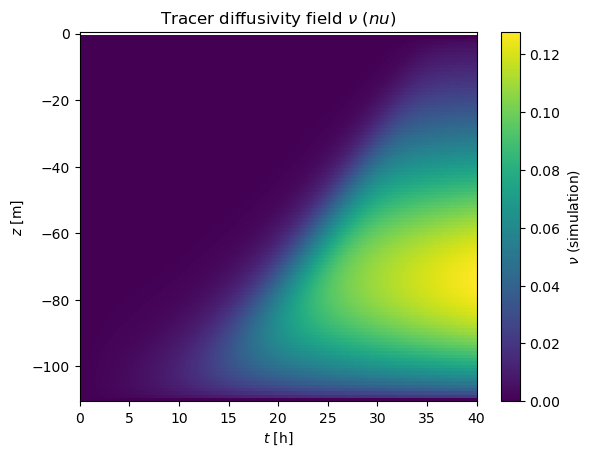

In [ ]:
t = torch.arange(2401) * dt
z = torch.linspace(-109.5, -0.5, 110)
zi = torch.linspace(-110., 0, 111)

t_idx, z_idx = torch.meshgrid(torch.arange(0, 2401, 1), torch.arange(0, 111, 1), indexing='ij')
nu1 = torch.sqrt(z_idx*(109-z_idx))*torch.tanh(t_idx/2000)*0.155*1/(1+torch.exp(-(0.0005*t_idx**2 - 20*z_idx)/150))*torch.exp(-(z_idx-25)**2/(2*40**2)) / 50
nu1.unsqueeze_(0).unsqueeze_(2)

plt.pcolormesh(t / 3600, zi, nu1.squeeze().T)
plt.xlabel('$t$ [h]')
plt.ylabel('$z$ [m]')
plt.title('Tracer diffusivity field $\\nu$ ($nu$)')
plt.colorbar(label='$\\nu$ (simulation)')
plt.show()

Note that the simulation uses a staggered grid, and the diffusivities are defined _between_ grid cells while concentrations are defined _on_ grid cells.

For computing the simulation, we use the TracerSimulationOperator object. It combines advection and diffusion operators and takes an NPZDModel as input. Note that it can be used to perform a single time step, but it also provides a simple rollout function:

In [ ]:
# define initial state and forcing conditions:
init_state = (8.15 + torch.sin(torch.arange(0, 110)*2*torch.pi/20)).unsqueeze(0).unsqueeze(0)
h1 = torch.ones((1, 2401, 1, 110), dtype=torch.float64)
scheme = "p2_pdm"

# define the operator:
transport_operator = TracerSimulationOperator(
    bc_up_type_dif="neumann", bc_down_type_dif="neumann", bc_up_value_dif=0., bc_down_value_dif=0.,
    bc_up_type_adv="flux", bc_down_type_adv="flux", bc_up_value_adv=0., bc_down_value_adv=0.,
    scheme_adv=scheme, conserve=False, implicitness=1., allow_negative=False, method_tridiag="paracr", model=model)

# perform a single step
state1 = transport_operator(init_state, dt, h1[:, 0], nu1[:, 0], lsource=None, qsource=None, w=None)

# perform rollout of the operator
simulation = transport_operator.integrate(init_state, dt, h1, nu1, lsource=None, qsource=None, w=None)

Note that _conserve_=False in the TracerSimulationOperator instantiation does not correspond to the sinking step, but to another step that corresponds to vertical motion of the fluid. As described above, that step should be performed in a non-conservative way in order to mimic 3d behaviour. However, this step is omitted as long as no vertical velocity is passed to the operator call.

Let us now plot the tracer concentration as a function of time and vertical position:

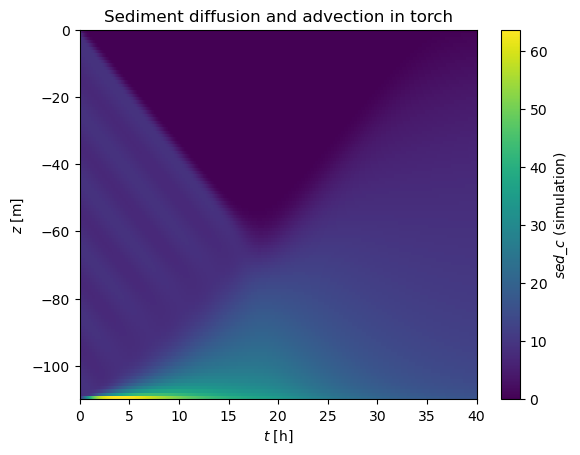

In [ ]:
t = torch.arange(2401) * dt
z = torch.linspace(-109.5, -0.5, 110)
zi = torch.linspace(-110., 0, 111)

plt.pcolormesh(t / 3600, z, simulation.squeeze().T)
plt.xlabel('$t$ [h]')
plt.ylabel('$z$ [m]')
plt.title('Sediment diffusion and advection in torch')
plt.colorbar(label='$sed\_c$ (simulation)')
plt.show()

At first, we observe a slow settling of the initial tracer profile. In particular, the tracer accumulates on the bottom of the water column. Then, we observe an onset of turbulent diffusion. Indeed, this looks reasonable given the diffusivity field.